# MNIST Fashion Neural Network Task

The aim of this task is to implement an MLP to classify images of fashion items from the MNIST Fashion dataset, achieving an accuracy of at least 80% on the test set. 

This dataset is a collection of grayscale images of various fashion items, such as clothing and accessories. Each image is of size 28x28 pixels and corresponds to one of the following 10 classes: T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, and Ankle boot.

### 1. Import Libraries

In [1]:
# PyTorch core
import torch
import torch.nn as nn
import torch.optim as optim

# PyTorch data + handling
from torchvision.datasets import FashionMNIST
from torchvision import transforms
from torch.utils.data import DataLoader, Subset, random_split

# sklearn metrics
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score, confusion_matrix

# data analysis + numerical computing
import numpy as np
import pandas as pd

# data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

### 2. Load  and Process Dataset

In [2]:
# set seed for reproducibility
torch.manual_seed(123)
np.random.seed(123)

In [3]:
# define transformation pipeline and normalise data
transform = transforms.Compose([
    # convert input to PyTorch tensors
    transforms.ToTensor(),
    # standardise tensor values
    transforms.Normalize((0.5,), (0.5,))
])

In [4]:
# load Fashion MNIST dataset
full_data = FashionMNIST(root='./data', train=True,
                         download=True, transform=transform)

# randomly subset dataset
indices = np.random.choice(len(full_data), size=10000, replace=False)
fashion = Subset(full_data, indices)

In [5]:
# define train/test split
train_size = int(0.8 * len(fashion))
test_size = len(fashion) - train_size

# split dataset into training and test set
train_data, test_data = random_split(fashion, [train_size, test_size])

# define train/validation split
val_train_size = int(0.8 * len(train_data))
val_size = len(train_data) - val_train_size

# split training set into training and validation set
train_final, val_data = random_split(train_data,
                                     [val_train_size, val_size])

In [6]:
# create batches to go over in a single iteration
train_loader = DataLoader(train_final, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)
val_loader = DataLoader(val_data, batch_size=64, shuffle=False)

### 3. MLP Training
#### 3.1. MLP Architecture
A ReLU activation function was applied here in an attempt to lower the possibility of the vanishing gradient problem. Softmax was not applied to the output layer, as 'nn.CrossEntropyLoss' applies softmax internally when calculating loss, so including it in the model as well would apply it twice.

In [7]:
class MLP(nn.Module):
    """
    A class representing a multilayer perceptron with one hidden
    layer.

    Attributes:
        input_size: number of input features.
        hidden_size: number of neurons in the hidden layer.
        output_size: number of output classes.
        fc1: fully connected layer from input to hidden layer.
        fc2: fully connected layer from hidden to output layer.
        activation: activation function to the output of the
                    hidden layer.

    Methods:
        __init__(self, input_size, hidden_size, output_size)
            builds the network layers.

        forward(self,x)
            runs the forward pass through the network.
        """
    def __init__(self, input_size, hidden_size, output_size):
        super(MLP, self).__init__()

        # initialise mlp structure
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size

        # initialise hidden and output layers
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, output_size)

        # activation function
        self.activation = nn.ReLU()

    def forward(self, x):
        # forward pass through the network
        x = self.activation(self.fc1(x))
        x = self.fc2(x)
        return x

#### 3.2. Train MLP Model

In [8]:
def train_model(train_loader, input_size, hidden_size, output_size,
                learning_rate, epochs, verbose=True):
    """Train MLP and return the trained model.

    Parameters:
        train_loader: DataLoader providing batches of inputs
                     and labels.
        input_size: number of input features.
        hidden_size: number of neurons in the hidden layer.
        output_size: number of output classes.
        learning_rate: learning rate for each weight update.
        epochs: number of full passes through the training data.
        verbose: whether to print loss after each epoch

    Returns:
        Trained mlp.
    """

    # set reproducibility seed
    torch.manual_seed(123)
    np.random.seed(123)

    # initialise mlp model
    mlp = MLP(input_size, hidden_size, output_size)

    # define the loss function
    criterion = nn.CrossEntropyLoss()

    # configure optimiser
    optimiser = optim.Adam(mlp.parameters(), lr=learning_rate)

    # training loop
    for epoch in range(epochs):
        for inputs, labels in train_loader:
            # flatten the batch of images
            inputs = inputs.view(inputs.size(0), -1)

            # forward pass
            outputs = mlp(inputs)

            # compute loss
            loss = criterion(outputs, labels)

            # zero gradients, backward pass, update weights
            optimiser.zero_grad()
            loss.backward()
            optimiser.step()

        # print loss per epoch
        if verbose:
            print(f'Epoch [{epoch+1}/{epochs}], '
                  f'Loss: {loss.item():.4f}')

    return mlp

In [9]:
# define input, hidden layer and output size
input_size = fashion[0][0].numel()
hidden_size = 64
output_size = 10

In [10]:
# train model using base parameters
base_mlp = train_model(train_loader, input_size, hidden_size,
                       output_size, learning_rate=0.01, epochs=10)

Epoch [1/10], Loss: 0.5560
Epoch [2/10], Loss: 0.5403
Epoch [3/10], Loss: 0.4582
Epoch [4/10], Loss: 0.5403
Epoch [5/10], Loss: 0.5148
Epoch [6/10], Loss: 0.3134
Epoch [7/10], Loss: 0.4102
Epoch [8/10], Loss: 0.3273
Epoch [9/10], Loss: 0.3234
Epoch [10/10], Loss: 0.2799


### 4. Evaluation
#### 4.1. Evaluation Function

In [11]:
def evaluate_model(model, data_loader):
    """
    Run data through mlp and return predictions and true values

    Parameters:
        model: trained mlp
        data_loader: DataLoader providing batches of inputs
                     and labels.

    Returns:
        all_preds: list of predicted labels.
        all_labels: list of true data labels."""

    model.eval()

    # empty lists for predicted and true labels
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in data_loader:
            # flatten the batch of images
            inputs = inputs.view(inputs.size(0), -1)

            # forward pass
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            # add outputs to list
            all_preds.extend(preds.tolist())
            all_labels.extend(labels.tolist())

    return all_preds, all_labels

#### 4.2. Validation Performance

In [12]:
# get predictions and labels for base model using validation set
base_v_pred, base_v_labels = evaluate_model(base_mlp, val_loader)

# calculate and print accuracy of validation set
base_v_accuracy = accuracy_score(base_v_labels, base_v_pred)
print(f'Base Model - Validation Set Accuracy: {base_v_accuracy:.2f}')

Base Model - Validation Set Accuracy: 0.83


The base model performs well, achieving 83% accuracy on the validation set. As this is already above the desired 80% accuracy, the model will be tuned further to see if performance can be improved.

### 5. Hyperparameter Tuning
Learning rate was chosen as the hyperparameter to tune, as it directly controls the size of each weight update during training. Too high a learning rate can cause the model to overshoot the optimal weights and become unstable, while too low a learning rate slows convergence and can leave the model stuck in a local minimum. Finding an optimal learning rate is therefore key to balancing training stability with how efficiently the loss reduces over time.

In [13]:
# list of learning rates to explore
learning_rates = [0.5, 0.1, 0.05, 0.01, 0.005, 0.001, 0.0005, 0.0001]
lr_results = {}

# calculate accuracy of MLPs with different learning rates
for lr in learning_rates:
    model = train_model(train_loader, input_size, hidden_size,
                        output_size, learning_rate=lr, epochs=10,
                        verbose=False)
    preds, labels = evaluate_model(model, val_loader)
    accuracy = accuracy_score(labels, preds)
    lr_results[lr] = accuracy

# print accuracy for each learning rate
lr_results = pd.DataFrame(list(lr_results.items()),
                          columns=['Learning Rate',
                                   'Validation Accuracy'])
print(lr_results)

   Learning Rate  Validation Accuracy
0         0.5000             0.105625
1         0.1000             0.306250
2         0.0500             0.616875
3         0.0100             0.833125
4         0.0050             0.844375
5         0.0010             0.846250
6         0.0005             0.848750
7         0.0001             0.805625


The model performed the best on the validation set at a learning rate of 0.0005; therefore, this value will be used for the final model. Accuracy improved steadily as the learning rate decreased, but this trend reversed once the learning rate became too small (0.0001), where accuracy dropped again. A more extreme, sharper drop was observed when the learning rate increased from 0.05 to 0.1 and 0.5, reflecting the instability caused by overly large weight updates.

### 6. Final Model Evaluation
#### 6.1. Final MLP Training

In [14]:
# train model using tuned hyperparameter
final_mlp = train_model(train_loader, input_size, hidden_size,
                        output_size, learning_rate=0.0005, epochs=10)

Epoch [1/10], Loss: 0.6366
Epoch [2/10], Loss: 0.6382
Epoch [3/10], Loss: 0.4961
Epoch [4/10], Loss: 0.4686
Epoch [5/10], Loss: 0.4939
Epoch [6/10], Loss: 0.3614
Epoch [7/10], Loss: 0.4191
Epoch [8/10], Loss: 0.4447
Epoch [9/10], Loss: 0.4298
Epoch [10/10], Loss: 0.3002


#### 6.2. Model Evaluation

In [15]:
# evaluate model using test data
final_preds, final_labels = evaluate_model(final_mlp, test_loader)

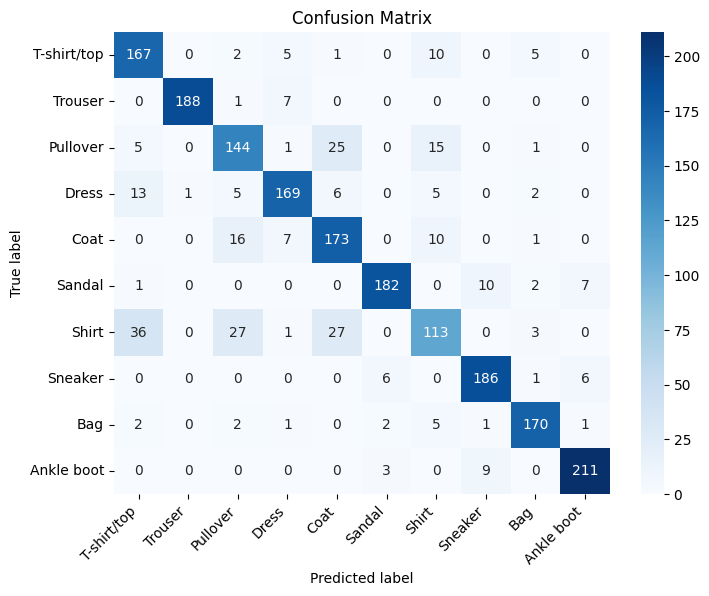

In [16]:
# confusion matrix
conf_matrix = confusion_matrix(final_labels, final_preds)

# assign class names
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# plot heatmap for confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)

plt.xticks(rotation=45, ha='right')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix')

plt.show()
plt.close()

The model struggles most with the Shirt class, often confusing it with T-shirt/top, Pullover, and Coat. Pullover and Coat also show some confusion with each other, likely because these are all visually similar upper-body clothing items. Classes with more distinct shapes, such as Trouser, Sandal, Sneaker, Bag, and Ankle boot, were classified with high accuracy and little confusion.

In [17]:
# calculate model metrics
f_accuracy = accuracy_score(final_labels, final_preds)
f_precision = precision_score(final_labels, final_preds, average='macro')
f_recall = recall_score(final_labels, final_preds, average='macro')
f_f1 = f1_score(final_labels, final_preds, average='macro')

# print metrics
print(f'Final Accuracy: {f_accuracy:.3f}')
print(f'Final Precision: {f_precision:.3f}')
print(f'Final Recall: {f_recall:.3f}')
print(f'Final F1-score: {f_f1:.3f}')

Final Accuracy: 0.852
Final Precision: 0.852
Final Recall: 0.852
Final F1-score: 0.850


The final model performs consistently well, with all four metrics rounding to 0.85. This tells us the model accurately predicts the class label 85% of the time. While the confusion matrix identifies Shirt, Pullover, and Coat as poor-performing classes, the high precision, recall and F1 scores tell us that, on average, the model is still highly precise.